# 05 · Table 1: inspectors vs. VisionCrack (paper Sec. 3, Table 1, Figs. *ex21*, *ex22*, *ex23*)

Five printed bars of known width (ET-1…ET-5 = 0.55–2.75 mm) are measured
* by **10 inspectors** with a crack-width gauge, and
* by **VisionCrack** on **10 captures**.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/` (10 PNG, `metadata.csv`, `inspectors.csv`) |
| **Outputs** | `results/tables/table1.csv`, `table1.tex`; `results/figures/ex21_roi.png`, `ex22_roi.png`, `ex23_roi.png` |
| **Runtime** | ~10 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [ ]:
from visioncrack.metrics import table1_summary
GT = np.array(vc.ET_GT_MM)
caps, inspectors = vc.load_table1()
roi = vc.preview_roi((2160, 3840), (430, 932))
print(roi, '| scale', round(vc.mm_per_px(roi.w), 5), 'mm/px')

Roi(x=682, y=2884, w=797, h=478) | scale 0.06274 mm/px


## Measure all 10 captures

In [ ]:
ms = [vc.measure_capture(vc.read_rgb(p), bb, roi) for p, bb in zip(caps.path, caps.bbox)]
cols = [f'ET-{i+1}' for i in range(5)]
vision = pd.DataFrame([m.widths_mm for m in ms], columns=cols,
                      index=[f'VisionCrack {i+1}' for i in range(len(ms))])
vision.round(3)

,ET-1,ET-2,ET-3,ET-4,ET-5
VisionCrack 1,0.644,1.066,1.757,2.229,2.823
VisionCrack 2,0.646,1.066,1.757,2.219,2.823
VisionCrack 3,0.650,1.066,1.757,2.228,2.823
VisionCrack 4,0.654,1.066,1.734,2.196,2.804
VisionCrack 5,0.659,1.066,1.740,2.196,2.810
VisionCrack 6,0.657,1.066,1.757,2.214,2.823
VisionCrack 7,0.648,1.066,1.757,2.196,2.798
VisionCrack 8,0.658,1.066,1.723,2.215,2.823
VisionCrack 9,0.646,1.066,1.732,2.196,2.790
VisionCrack 10,0.657,1.066,1.736,2.196,2.823


## Summary rows
`mean` is the row labelled *MAE\** in the paper, and `abs_bias` = |mean − GT| is *MAE\* vs. GT*.

In [ ]:
s_ins = table1_summary(inspectors.to_numpy(), GT)
s_vc = table1_summary(vision.to_numpy(), GT)
display(s_ins.round(4)); display(s_vc.round(4))

,ET-1,ET-2,ET-3,ET-4,ET-5,Overall
mean,0.540,1.2700,1.8750,2.425,2.9250,1.8070
std,0.041,0.1536,0.1188,0.123,0.1647,0.1202
abs_bias,0.010,0.1700,0.2250,0.225,0.1750,0.1610


,ET-1,ET-2,ET-3,ET-4,ET-5,Overall
mean,0.6519,1.0665,1.7448,2.2085,2.8141,1.6972
std,0.0054,0.0000,0.0125,0.0136,0.0120,0.0087
abs_bias,0.1019,0.0335,0.0948,0.0085,0.0641,0.0606


### Matching the published numbers
The paper's summary rows are computed from the **3-decimal VisionCrack values printed in Table 1**, not from the unrounded widths.
For STD this matters at ET-4: 0.0136 unrounded vs. 0.0133 from the printed values.
The per-target mean and STD are then rounded **half-up** (inspectors to 2 decimals, VisionCrack to 3).
The bias is taken from the *rounded* mean, and the *Overall* column averages the five targets.
Doing the same reproduces every summary number in Table 1. Unrounded, the values differ only in the 3rd decimal
(e.g. inspector bias 0.161 vs. 0.164).

In [ ]:
s_vc_pub = table1_summary(vision.round(3).to_numpy(), GT)   # from the values as printed
s_vc_pub.round(4)

,ET-1,ET-2,ET-3,ET-4,ET-5,Overall
mean,0.6519,1.066,1.7450,2.2085,2.814,1.6971
std,0.0054,0.000,0.0126,0.0133,0.012,0.0087
abs_bias,0.1019,0.034,0.0950,0.0085,0.064,0.0607


In [ ]:
from visioncrack.metrics import half_up

def overall_as_published(summary, nd):
    s = summary.drop(columns='Overall')
    mean, std = half_up(s.loc['mean'], nd), half_up(s.loc['std'], nd)
    return pd.Series({'mean': mean.mean(), 'std': std.mean(), 'abs_bias': np.abs(mean - GT).mean()})

pub_ins = overall_as_published(s_ins, 2)
pub_vc = overall_as_published(s_vc_pub, 3)
display(pd.DataFrame({'Inspectors': pub_ins, 'VisionCrack': pub_vc}).round(4))

# --- regression check against the paper ---
assert np.allclose(vision.mean().round(3), [0.652, 1.066, 1.745, 2.209, 2.814]), 'VisionCrack means changed'
assert np.allclose(half_up(s_vc_pub.loc['std', cols], 3), [0.005, 0.000, 0.013, 0.013, 0.012])
assert np.allclose(half_up(s_ins.loc['std', cols], 2), [0.04, 0.15, 0.12, 0.12, 0.16])
assert np.allclose(s_vc.loc['abs_bias', cols].round(3), [0.102, 0.034, 0.095, 0.009, 0.064])
assert round(pub_vc['abs_bias'], 4) == 0.0608 and round(pub_vc['std'], 4) == 0.0086
assert round(pub_ins['abs_bias'], 3) == 0.164 and round(pub_ins['std'], 3) == 0.118
print('✓ matches the published table')
imp_mae = 1 - pub_vc['abs_bias'] / pub_ins['abs_bias']; imp_std = 1 - pub_vc['std'] / pub_ins['std']
print(f'MAE improvement {imp_mae:.0%}, STD reduction {imp_std:.0%}')

,Inspectors,VisionCrack
mean,1.810,1.6972
std,0.118,0.0086
abs_bias,0.164,0.0608


✓ matches the published table
MAE improvement 63%, STD reduction 93%


## Export Table 1

In [ ]:
tab = pd.concat([
    pd.DataFrame([GT], columns=cols, index=['GT']),
    inspectors[cols],
    s_ins[cols].rename(index={'mean': 'Inspector MAE*', 'std': 'Inspector STD', 'abs_bias': 'Inspector MAE* vs GT'}),
    vision,
    s_vc_pub[cols].rename(index={'mean': 'VisionCrack MAE**', 'std': 'VisionCrack STD', 'abs_bias': 'VisionCrack MAE** vs GT'}),
])
tab.to_csv(TAB / 'table1.csv', float_format='%.4f')
tab.round(3).to_latex(TAB / 'table1.tex', float_format='%.3f')
tab.round(3)

,ET-1,ET-2,ET-3,ET-4,ET-5
GT,0.550,1.100,1.650,2.200,2.750
Inspector 1,0.500,1.400,1.900,2.400,2.900
Inspector 2,0.500,1.000,2.000,2.500,3.000
Inspector 3,0.500,1.300,1.900,2.400,3.000
Inspector 4,0.550,1.500,2.000,2.500,3.000
Inspector 5,0.500,1.000,2.000,2.500,3.000
Inspector 6,0.600,1.400,2.000,2.500,2.900
Inspector 7,0.530,1.250,1.750,2.250,3.250
Inspector 8,0.550,1.250,1.750,2.250,2.750
Inspector 9,0.620,1.300,1.700,2.300,2.600


## Figures

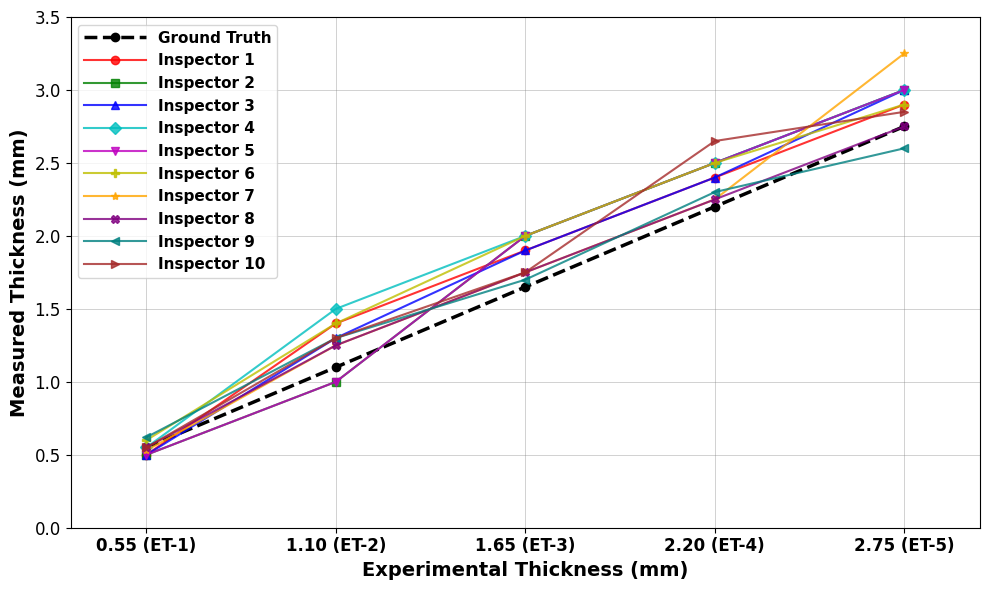

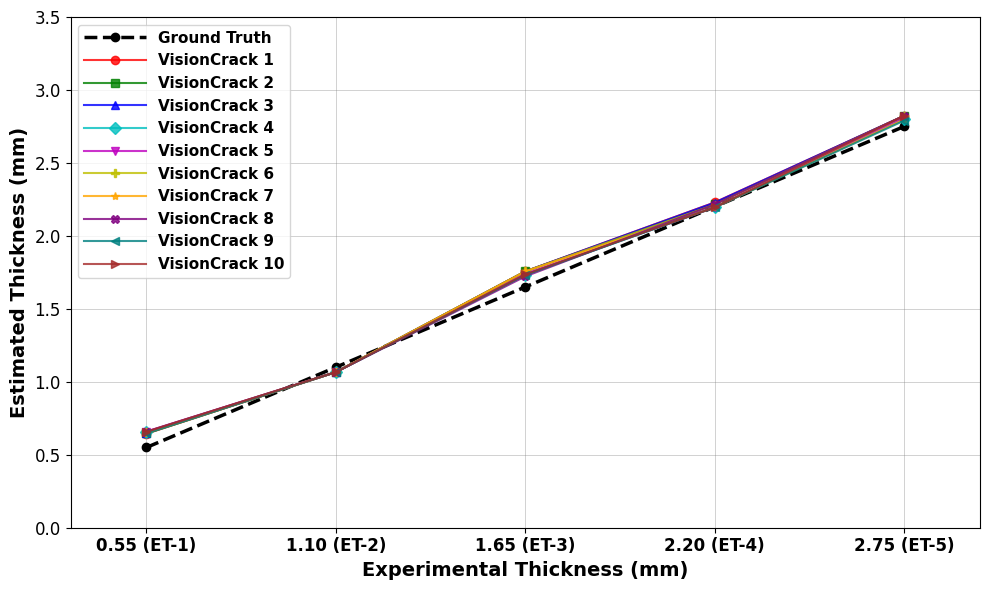

In [ ]:
from visioncrack.plotting import COLORS, MARKERS, paper_axes

def lines(df, name, ylabel):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(GT, 'o--', lw=2.5, color='black', label='Ground Truth')
    for i, (idx, row) in enumerate(df.iterrows()):
        ax.plot(row.values, marker=MARKERS[i % 10], lw=1.5, alpha=.8, color=COLORS[i % 10], label=idx)
    paper_axes(ax, 'Experimental Thickness (mm)', ylabel)
    plt.savefig(FIG / name, dpi=300); plt.show()

lines(inspectors[cols], 'ex21_roi.png', 'Measured Thickness (mm)')   # Fig. ex21
lines(vision, 'ex22_roi.png', 'Estimated Thickness (mm)')            # Fig. ex22

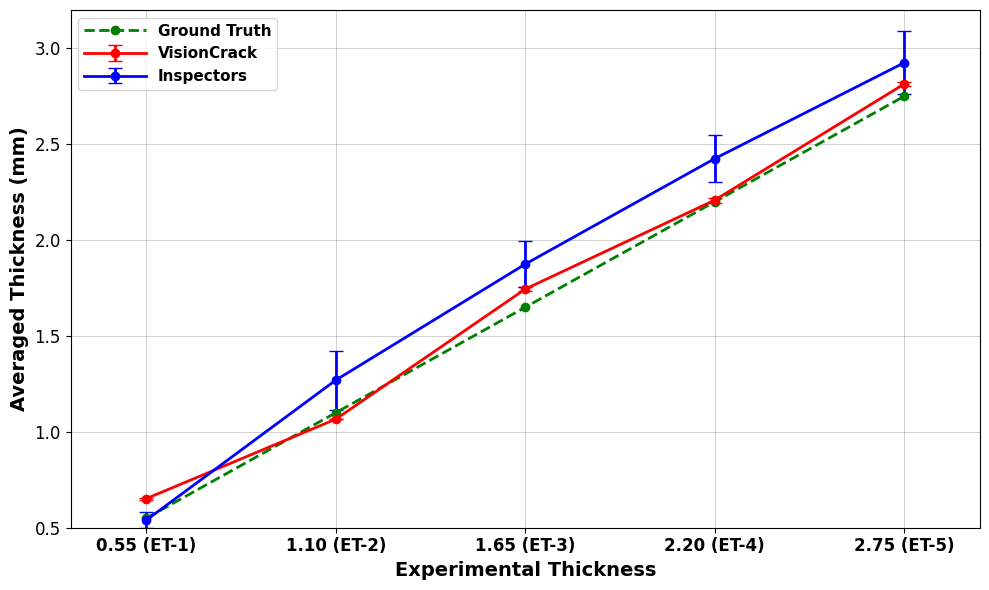

In [ ]:
# Fig. ex23: mean ± std of both methods vs GT
x = np.arange(5)
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(x, vision.mean(), yerr=vision.std(ddof=0), fmt='o-', capsize=5, color='red', lw=2, label='VisionCrack')
ax.errorbar(x, inspectors[cols].mean(), yerr=inspectors[cols].std(ddof=0), fmt='o-', capsize=5, color='blue', lw=2, label='Inspectors')
ax.plot(x, GT, 'o--', color='green', lw=2, label='Ground Truth')
paper_axes(ax, 'Experimental Thickness', 'Averaged Thickness (mm)', ylim=(0.5, 3.2))
plt.savefig(FIG / 'ex23_roi.png', dpi=300); plt.show()

## Note on the error metric

The paper's *MAE vs. GT* is |**mean** of 10 readings − GT|, averaged over targets. That is the **absolute bias of the mean**.
It is not the usual MAE, which is the mean of |**each reading** − GT|.

* For VisionCrack the two are almost identical, because all readings sit on the same side of GT.
* For inspectors they differ, because readings scatter on both sides of GT, so errors cancel in the mean. The bias of the mean therefore *understates* inspector error, which makes the comparison conservative in VisionCrack's favour.

The per-reading version is shown below, together with the signed bias. The signed bias shows that VisionCrack reads ET-1 too wide in every capture.
The conclusion holds either way: VisionCrack's per-reading MAE is far below the inspectors'.

In [ ]:
from visioncrack.metrics import per_reading_error
pr = pd.concat({'Inspectors': per_reading_error(inspectors[cols].to_numpy(), GT),
                'VisionCrack': per_reading_error(vision.to_numpy(), GT)})
pr.to_csv(TAB / 'table1_per_reading_error.csv', float_format='%.4f')
pr.round(4)

ET-1    ET-2    ET-3    ET-4    ET-5  Overall
Inspectors  mae   0.0340  0.2100  0.2250  0.2250  0.2050   0.1798
            bias -0.0100  0.1700  0.2250  0.2250  0.1750   0.1570
            rmse  0.0422  0.2291  0.2545  0.2564  0.2403   0.2045
VisionCrack mae   0.1019  0.0335  0.0948  0.0128  0.0641   0.0614
            bias  0.1019 -0.0335  0.0948  0.0085  0.0641   0.0472
            rmse  0.1020  0.0335  0.0957  0.0160  0.0652   0.0625